# Benchmarking Expertise Retrieval for Peer Review: Evaluating Statistical and Neural Representations for the Reviewer Assignment Problem

Anonymized data: score matrices have reviewers as rows and proposals as columns. The ground truth file maps each proposal to its designated reviewer.

The data does not release reviewer names, proposal text, or ESO identifiers. The script for converting raw text proposals and reviewer text into score matrices is provided, use the score_matrices.py script. 

## 1. Load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.ticker import ScalarFormatter
from sklearn.metrics import ndcg_score
import numpy as np
import json

In [2]:
#score matrices
with np.load("data/score_matrices.npz") as data:
    score_matrices = {
        name: data[name]
        for name in data.files
    }
#expertise_labels for NDCG calculation
expertise_labels = pd.read_json("data/expertise_labels.json")

#Mapping between reviewers and proposals 
with open("data/ground_truth.json", "r") as f:
    ground_truth = json.load(f)

print(f"{len(score_matrices)} score matrices, {len(ground_truth)} ground-truth proposals")

18 score matrices, 435 ground-truth proposals


In [3]:
score_matrices.keys()

dict_keys(['Keywords', 'TF-IDF', 'TF-IDF (max-sim)', 'LDA', 'Sentence Transformer (mean)', 'Sentence Transformer (max)', 'Sentence Transformer (max-sim)', 'Sentence Transformer (topk-sim)', 'SPECTER (mean)', 'SPECTER (max)', 'SPECTER (max-sim)', 'SPECTER (topk-sim)', 'GPT-4o mini', 'GPT-4o mini (retrieve-rerank)', 'GPT-4o mini (decomposition)', 'GPT-5.6-luna (pointwise)', 'GPT-5.6-luna (retrieve-rerank)', 'GPT-5.6-luna (decomposition)'])

In [4]:
DISPLAY_METHODS = [
    "Keywords", "TF-IDF", "LDA",
    "Sentence Transformer (max-sim)",
    "SPECTER (max-sim)",
    "GPT-5.6-luna (pointwise)",
]

DISPLAY_METHODS = [name for name in DISPLAY_METHODS
                   if name in score_matrices]

print("Plotting:", DISPLAY_METHODS)

Plotting: ['Keywords', 'TF-IDF', 'LDA', 'Sentence Transformer (max-sim)', 'SPECTER (max-sim)', 'GPT-5.6-luna (pointwise)']


## 2. Ranking metrics

In [5]:
def proposal_metrics(scores, truth, k_values=[25], min_candidates=1):
    """Compute proposal-level ranking metrics from a NumPy score matrix.
    """
    scores_df = pd.DataFrame(scores)
    
    rows = []
    for proposal_id, reviewer_id in truth.items():
        col = scores_df[int(proposal_id) - 1].dropna()
        
        rank = col.rank(ascending=False, method="average").iloc[int(reviewer_id) - 1]
        others = col.drop(index=int(reviewer_id) - 1).to_numpy()
        z = (col[int(reviewer_id) - 1] - others.mean()) / (others.std(ddof=1) if others.std() > 0 else np.nan)

        row = {"proposal_id": proposal_id, "rank": rank, "mrr": 1 / rank, "z": z}
        for k in k_values:
            row[f"hit@{k}"] = int(rank <= k)
        rows.append(row)
    return pd.DataFrame(rows).set_index("proposal_id")

In [6]:
all_metrics = {name: proposal_metrics(score_matrices[name], ground_truth)
               for name in DISPLAY_METHODS}
for name, m in all_metrics.items():
    print(f"{name}: {len(m)} proposals evaluated")

Keywords: 435 proposals evaluated
TF-IDF: 435 proposals evaluated
LDA: 435 proposals evaluated
Sentence Transformer (max-sim): 435 proposals evaluated
SPECTER (max-sim): 435 proposals evaluated
GPT-5.6-luna (pointwise): 435 proposals evaluated


In [7]:
all_metrics = {name: proposal_metrics(score_matrices[name], ground_truth)
               for name in DISPLAY_METHODS}

summary = pd.DataFrame({
    name: {
        "MRR": metrics.mrr.mean(),
        "Hit@25": metrics["hit@25"].mean(),
        "Median rank": metrics["rank"].median(),
        "Mean rank": metrics["rank"].mean(),
        "N": len(metrics),
    }
    for name, metrics in all_metrics.items()
}).T.sort_values("MRR", ascending=False)
summary

,MRR,Hit@25,Median rank,Mean rank,N
TF-IDF,0.362845,0.740230,5.0,51.034483,435.0
GPT-5.6-luna (pointwise),0.344071,0.786207,5.0,36.860920,435.0
Sentence Transformer (max-sim),0.310311,0.701149,7.0,49.193103,435.0
Keywords,0.268212,0.696552,9.0,29.004598,435.0
SPECTER (max-sim),0.255580,0.606897,12.0,62.390805,435.0
LDA,0.123956,0.427586,34.0,83.725287,435.0


## 3. Main figures

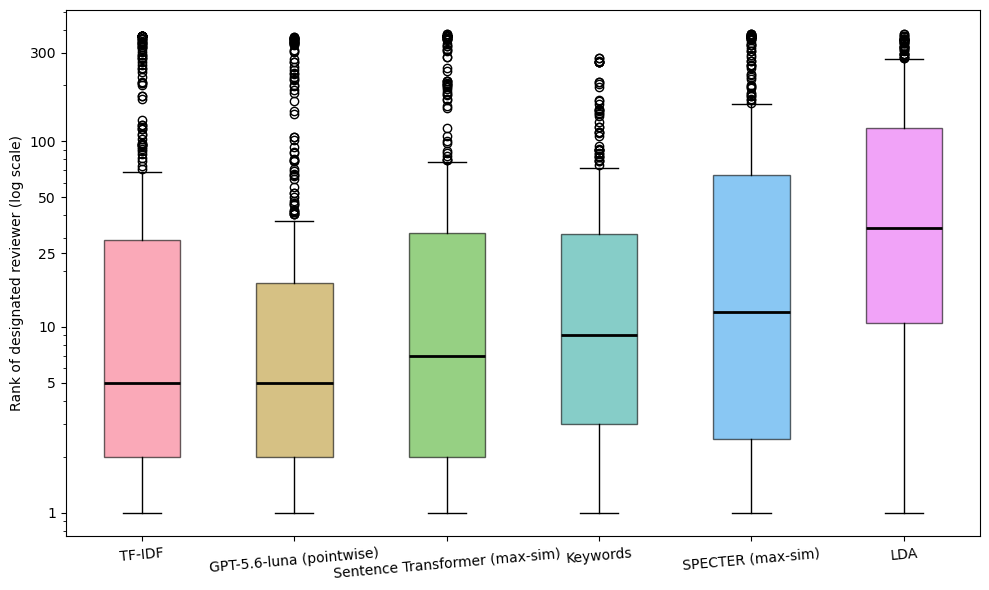

In [8]:
ordered = sorted(DISPLAY_METHODS, key=lambda name: all_metrics[name]["rank"].median())
fig, ax = plt.subplots(figsize=(10, 6))
box = ax.boxplot([all_metrics[name]["rank"] for name in ordered],
                 patch_artist=True, tick_labels=ordered, showfliers=True)

for patch, color in zip(box["boxes"], sns.color_palette("husl", len(ordered))):
    patch.set_facecolor(color)
    patch.set_alpha(.6)
for median in box["medians"]:
    median.set(color="black", linewidth=2)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(ScalarFormatter())
ax.set_yticks([1, 5, 10, 25, 50, 100, 300])
ax.set_ylabel("Rank of designated reviewer (log scale)")
ax.tick_params(axis="x", rotation= 5)
plt.tight_layout()
plt.show()

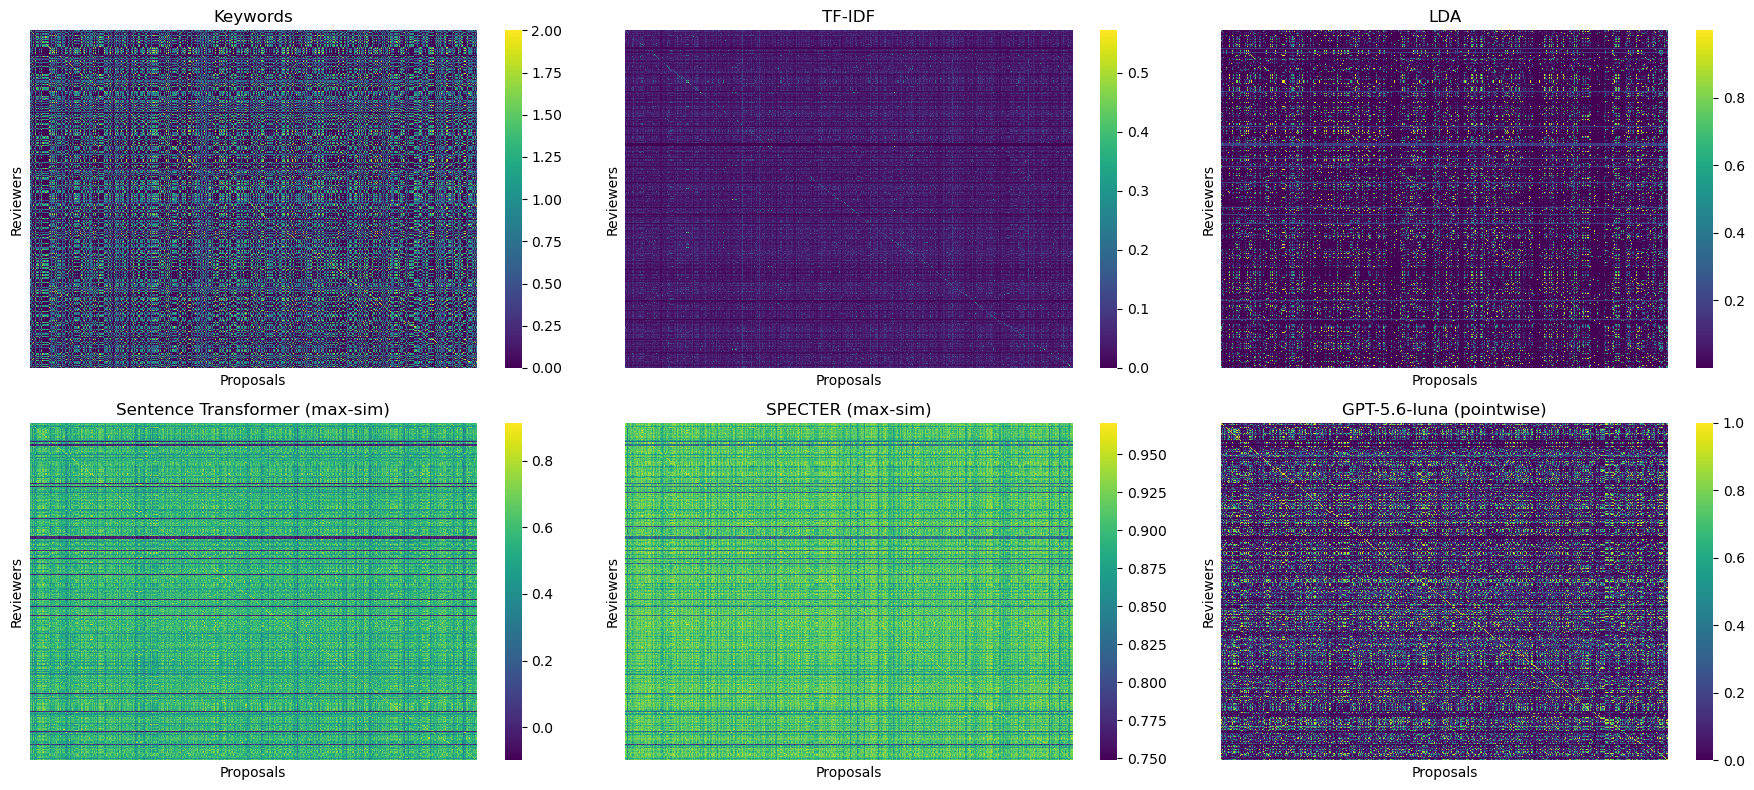

In [9]:
ncols = min(3, len(DISPLAY_METHODS))
nrows = int(np.ceil(len(DISPLAY_METHODS) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 4*nrows), squeeze=False)
for axis, name in zip(axes.flat, DISPLAY_METHODS):
    sns.heatmap(score_matrices[name], cmap="viridis",
                xticklabels=False, yticklabels=False, ax=axis)
    axis.set_title(name)
    axis.set_xlabel("Proposals")
    axis.set_ylabel("Reviewers")
for axis in axes.flat[len(DISPLAY_METHODS):]:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 5. Self-reported expertise evaluation

This section uses only released anonymized expertise labels. It is skipped if `expertise_labels.pkl` is absent. Labels should contain `reviewer_id`, `proposal_id`, and `expertise_label` with values `Expert`, `Intermediate`, or `Non-Expert`.

In [10]:
labels = expertise_labels.copy()
labels["reviewer_id"] = labels["reviewer_id"].astype(int)
labels["proposal_id"] = labels["proposal_id"].astype(int)
relevance = {"Expert": 10, "Intermediate": 2, "Non-Expert": 0}

rows = []
for proposal_id, group in labels.groupby("proposal_id"):
    for method in DISPLAY_METHODS:
        matrix = np.asarray(score_matrices[method])
        proposal_idx = proposal_id - 1
        reviewer_idx = group["reviewer_id"].to_numpy() - 1
        in_bounds = ((0 <= proposal_idx < matrix.shape[1])
                     & (reviewer_idx >= 0)
                     & (reviewer_idx < matrix.shape[0]))
        method_group = group.loc[in_bounds]
        reviewer_idx = reviewer_idx[in_bounds]
        scores = (matrix[reviewer_idx, proposal_idx]
                  if len(reviewer_idx) else np.array([], dtype=float))
        rel = method_group.expertise_label.map(relevance).fillna(0).to_numpy()
        rows.append({
            "proposal_id": proposal_id, "Method": method,
            "NDCG": ndcg_score([rel], [np.asarray(scores)])
        })

In [11]:
ndcg_results = pd.DataFrame(rows)
ndcg_summary = (ndcg_results.groupby("Method").NDCG.mean()
                .sort_values(ascending=False).to_frame("Mean NDCG"))
ndcg_summary

,Mean NDCG
Method,
GPT-5.6-luna (pointwise),0.881114
TF-IDF,0.846591
Sentence Transformer (max-sim),0.846492
SPECTER (max-sim),0.834844
LDA,0.797815
Keywords,0.793431
